# 02 — Tutorial notebook

*Companion to:* **Geochemistry-informed prediction and layered transferability of soil organic carbon in the Ganges Delta**.

This notebook walks through the analyses **with explanatory narrative**, so a reader unfamiliar with the design can understand *why* each step exists. It ends with empty exploration cells for extending the work (try other models, deltas, or sensitivity sweeps).

**Audience:** authors onboarding new collaborators, students, or anyone learning spatial cross-validation or cross-delta transferability for SOC.

**Prereqs:** Python 3.11, `requirements.txt` in the bundle root.

## 0. Setup

We work from `reproducibility/`; the scripts and data live one level above this notebook. Everything below is deterministic (random seed = 42).

In [1]:
# Environment + path setup. The notebook lives in reproducibility/notebooks/;
# inputs are in ../data/ and the analysis scripts are in ../scripts/.
import sys, os, json, pickle
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")  # headless-safe; remove for inline interactive figures
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "scripts").is_dir() and not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
SCRIPTS = ROOT / "scripts"
DATA    = ROOT / "data"
print(f"ROOT    = {ROOT}")
print(f"DATA    = {DATA}")
print(f"SCRIPTS = {SCRIPTS}")

# Make scripts importable AND chdir there so the scripts' own relative paths
# resolve as if they were being run from scripts/.
sys.path.insert(0, str(SCRIPTS))
os.chdir(SCRIPTS)
print(f"cwd     = {os.getcwd()}")

# Pin deterministic state
np.random.seed(42)

# Common plotting defaults
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "savefig.dpi": 200,
                     "axes.titleweight": "bold"})


ROOT    = <bundle>
DATA    = <bundle>/data
SCRIPTS = <bundle>/scripts
cwd     = <bundle>/scripts


## 1. The field data

We sampled 20 sites across four geomorphological zones of the Ganges Delta (Hossain et al. 2015) — Tidal Active, Active Delta, Mature Delta, Moribund Delta — five sites per zone, five depth intervals per site (0–20, 20–40, …, 80–100 cm), yielding 100 samples. Each was analysed for 14 physicochemical properties.

Why we kept the data design as nested replicates rather than pseudo-independent samples: because the 5 depths within a pit are spatially autocorrelated, mixing them across train/test inflates apparent model skill. (See section 3.)

In [2]:
# Load the primary field dataset (100 samples × 14 properties).
soc = pd.read_csv(DATA / "GangesSOC.csv")
soc.columns = [c.strip() for c in soc.columns]
print(f"GangesSOC.csv: {len(soc)} samples × {len(soc.columns)} variables")
print("first columns:", list(soc.columns)[:10])

# Zone-level files (5 locations per zone, 25 samples per zone, 4 zones)
zones = {}
for z, f in [("Tidal Active","Tidal.csv"), ("Active Delta","Active.csv"),
             ("Mature Delta","Mature.csv"), ("Moribund Delta","Moribund.csv")]:
    zc = pd.read_csv(DATA / f); zc.columns = [c.strip() for c in zc.columns]
    zones[z] = zc
print("samples per zone:", {z: len(d) for z, d in zones.items()})


GangesSOC.csv: 100 samples × 20 variables
first columns: ['Sample', 'Bulk Density', 'Moisture', 'Sand', 'Silt', 'Clay', 'pH', 'EC', 'OM', 'TN']
samples per zone: {'Tidal Active': 25, 'Active Delta': 25, 'Mature Delta': 25, 'Moribund Delta': 25}


In [3]:
# Quick descriptive look at SOC stock by zone
import pandas as pd
frames = []
for z, d in zones.items():
    frames.append(pd.DataFrame({"zone": z, "SOC_stock": d["SOC Stock"]}))
long = pd.concat(frames)
long.groupby("zone")["SOC_stock"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
zone,,,,,,,,
Active Delta,25.0,28.5,15.2,8.9,16.4,23.5,38.5,69.2
Mature Delta,25.0,8.4,8.6,1.1,3.0,4.5,12.2,31.8
Moribund Delta,25.0,16.2,10.5,4.3,9.4,12.0,20.2,40.7
Tidal Active,25.0,127.3,78.7,31.4,61.3,104.9,207.7,275.5


## 2. H1 — geochemical controls and the 'EC paradox'

Pearson correlations on the pooled 100-sample dataset show electrical conductivity (EC), cation exchange capacity (CEC), and soil moisture as the strongest geochemical correlates of SOC. But the *between-zone* contrast is very different from the *within-zone* one — the EC paradox.

We run the per-zone analysis to expose this. Sign reversals (TN positive in one zone, negative in another) demonstrate why pooling correlations can be misleading in heterogeneous systems.

In [4]:
"""
Per-zone correlation analysis (addresses Reviewer 3, comment 5): because the four
geomorphological zones are distinct biogeochemical settings, soil property--SOC
correlations are computed separately within each zone, not only pooled. Also
substantiates the "EC paradox" (strong between-zone, weak within-zone) and the
TN sign-reversal that produces TN's near-zero pooled correlation.

Correlations use SOC concentration (consistent with the H1 choice; see A5/R3-1).
Run:  python3 per_zone_correlations.py  ->  per_zone_correlations.csv
"""
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

DATA = Path.cwd().parent / "data"
ZONES = {"Tidal Active": "Tidal.csv", "Active Delta": "Active.csv",
         "Mature Delta": "Mature.csv", "Moribund Delta": "Moribund.csv"}
PREDS = ["EC", "CEC", "Moisture", "Clay", "pH", "TN"]
Y = "SOCC"  # SOC concentration

frames = []
for zname, f in ZONES.items():
    d = pd.read_csv(DATA / f); d.columns = [c.strip() for c in d.columns]; d["zone"] = zname
    frames.append(d)
alld = pd.concat(frames, ignore_index=True)

rows = []
for p in PREDS:
    rec = {"predictor": p}
    r, pv = stats.pearsonr(alld[p], alld[Y])
    rec["Overall"] = f"{r:+.2f}{'*' if pv < 0.05 else ''}"
    for zname in ZONES:
        sub = alld[alld["zone"] == zname]
        r, pv = stats.pearsonr(sub[p], sub[Y])
        rec[zname] = f"{r:+.2f}{'*' if pv < 0.05 else ''}"
    rows.append(rec)

res = pd.DataFrame(rows)
res.to_csv(Path.cwd() / "per_zone_correlations.csv", index=False)
print(res.to_string(index=False))
print("\n* p < 0.05; n = 100 overall, n = 25 per zone; correlations vs SOC concentration.")

# --- display the result table inline ---
pd.read_csv("per_zone_correlations.csv")

predictor Overall Tidal Active Active Delta Mature Delta Moribund Delta
       EC  +0.66*        -0.20        +0.34       +0.65*         +0.55*
      CEC  +0.63*        -0.19        -0.14       +0.62*          +0.30
 Moisture  +0.56*       +0.54*        -0.23        -0.11          +0.29
     Clay  +0.33*        -0.30        -0.24       +0.47*          +0.30
       pH  +0.25*       +0.61*        -0.29       -0.67*          -0.37
       TN   +0.04       -0.79*       +0.73*        +0.35          +0.27

* p < 0.05; n = 100 overall, n = 25 per zone; correlations vs SOC concentration.


,predictor,Overall,Tidal Active,Active Delta,Mature Delta,Moribund Delta
0,EC,+0.66*,-0.20,+0.34,+0.65*,+0.55*
1,CEC,+0.63*,-0.19,-0.14,+0.62*,+0.30
2,Moisture,+0.56*,+0.54*,-0.23,-0.11,+0.29
3,Clay,+0.33*,-0.30,-0.24,+0.47*,+0.30
4,pH,+0.25*,+0.61*,-0.29,-0.67*,-0.37
5,TN,+0.04,-0.79*,+0.73*,+0.35,+0.27


**Notice** rows where the pooled and per-zone signs disagree (TN, pH). These are the strongest argument for zone-stratified analysis rather than pooling.

## 3. H3 — honest cross-validation for nested-sample data

A random 5-fold split puts samples from the same site in both training and test folds. Because nearby samples are correlated, this lets the model 'memorise' the site rather than learn the underlying relationship — apparent R² is inflated.

The fix is **GroupKFold by location**: whole sites are held out so the test set is genuinely spatially separated. We compare four schemes:
* Random 5-fold (the leaky one),
* Location-grouped 5-fold (the authoritative one),
* Leave-Location-Out (20-fold; less conservative because one site at a time),
* Leave-Zone-Out (4-fold; the strictest test — generalisation across zones).

We also drop OM (Walkley-Black organic matter) up front: it correlates r = 0.996 with SOC because they measure essentially the same thing. Including OM made the model look good (R² ≈ 0.98) for the wrong reason.

In [5]:
"""
Leak-free spatial cross-validation for the SOC ML models (addresses R1-13, R1-25, R3-13).

The 100 samples are 5 depths x 20 field locations (pseudoreplication). Random k-fold CV
splits same-location samples across train and test, leaking information and inflating R^2.
This script quantifies that optimism by comparing, for the same model and an in-fold
preprocessing pipeline (StandardScaler fit only on the training fold):

  * random 5-fold CV          (the leaky scheme used originally)
  * location-grouped 5-fold   (GroupKFold by location -- leak-free spatial)
  * Leave-Location-Out (LOLO) (20-fold, group = location)
  * Leave-Zone-Out (LZO)      (4-fold, group = geomorphological zone)

Pooled R^2 is computed over the concatenated held-out predictions (matching how the
manuscript reports CV R^2). Models: GBR (best traditional model) and two simple
baselines (EC-only OLS, full OLS).

Run:  python3 ml_spatial_cv.py   ->  ml_spatial_cv_results.csv
"""

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, GroupKFold, LeaveOneGroupOut
from sklearn.metrics import r2_score, mean_squared_error

ROOT = Path.cwd().parent
DATA = ROOT / "data"

# ---- data ------------------------------------------------------------------
feat = pd.read_csv(DATA / "features_preprocessed.csv")
y = pd.read_csv(DATA / "target.csv").iloc[:, 0].values.astype(float)
soc = pd.read_csv(DATA / "GangesSOC.csv"); soc.columns = [c.strip() for c in soc.columns]

loc = soc["Location"].values
loc_groups = pd.factorize(loc)[0]

zone_map = {}
for z, f in [("Tidal", "Tidal.csv"), ("Active", "Active.csv"),
             ("Mature", "Mature.csv"), ("Moribund", "Moribund.csv")]:
    zf = pd.read_csv(DATA / f); zf.columns = [c.strip() for c in zf.columns]
    for L in zf["Location"].unique():
        zone_map[L] = z
zone = np.array([zone_map.get(L, "?") for L in loc])
zone_groups = pd.factorize(zone)[0]

# Drop target-derived / leakage columns: OM (r=0.996 with SOC, per manuscript), and
# any SOC component if present. The manuscript states all models exclude OM.
LEAK = [c for c in feat.columns if c.strip().upper() in
        {"OM", "SOC", "SOCC", "SOCD", "SOC STOCK", "SOC_STOCK"}]
feat_model = feat.drop(columns=LEAK)
print(f"dropped leakage columns: {LEAK}  ->  {feat_model.shape[1]} predictors")

X_full = feat_model.values
X_ec = feat[["EC"]].values

# ---- helpers ---------------------------------------------------------------
def pooled_cv(make_model, X, y, splitter, groups=None):
    """Return pooled R^2 and RMSE over concatenated held-out predictions."""
    preds = np.full(len(y), np.nan)
    it = splitter.split(X, y, groups) if groups is not None else splitter.split(X, y)
    for tr, te in it:
        m = make_model()
        m.fit(X[tr], y[tr])
        preds[te] = m.predict(X[te])
    return r2_score(y, preds), float(np.sqrt(mean_squared_error(y, preds)))

def gbr():  return make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42))
def ols():  return make_pipeline(StandardScaler(), LinearRegression())

random5 = KFold(n_splits=5, shuffle=True, random_state=42)
group5  = GroupKFold(n_splits=5)
logo    = LeaveOneGroupOut()

# ---- runs ------------------------------------------------------------------
rows = []
def add(model, scheme, r2, rmse, ngroups=""):
    rows.append({"model": model, "cv_scheme": scheme, "R2": round(r2, 3),
                 "RMSE": round(rmse, 1), "n_folds_or_groups": ngroups})

# GBR across all four schemes
r, e = pooled_cv(gbr, X_full, y, random5);                       add("GBR (14 feat)", "random 5-fold (leaky)", r, e, 5)
r, e = pooled_cv(gbr, X_full, y, group5, loc_groups);           add("GBR (14 feat)", "location-grouped 5-fold", r, e, 5)
r, e = pooled_cv(gbr, X_full, y, logo, loc_groups);             add("GBR (14 feat)", "Leave-Location-Out (LOLO)", r, e, 20)
r, e = pooled_cv(gbr, X_full, y, logo, zone_groups);            add("GBR (14 feat)", "Leave-Zone-Out (LZO)", r, e, 4)

# baselines under random vs grouped
r, e = pooled_cv(ols, X_ec, y, random5);                        add("EC-only OLS", "random 5-fold (leaky)", r, e, 5)
r, e = pooled_cv(ols, X_ec, y, group5, loc_groups);            add("EC-only OLS", "location-grouped 5-fold", r, e, 5)
r, e = pooled_cv(ols, X_full, y, random5);                      add("Full OLS", "random 5-fold (leaky)", r, e, 5)
r, e = pooled_cv(ols, X_full, y, group5, loc_groups);          add("Full OLS", "location-grouped 5-fold", r, e, 5)

res = pd.DataFrame(rows)
res.to_csv(Path.cwd() / "ml_spatial_cv_results.csv", index=False)

# ---- report ----------------------------------------------------------------
print(res.to_string(index=False))
gbr_rand = res[(res.model.str.startswith("GBR")) & (res.cv_scheme.str.contains("random"))]["R2"].iloc[0]
gbr_grp  = res[(res.model.str.startswith("GBR")) & (res.cv_scheme.str.contains("location-grouped"))]["R2"].iloc[0]
print(f"\nGBR optimism from pseudoreplication: random {gbr_rand:.3f} -> location-grouped {gbr_grp:.3f} "
      f"(drop {gbr_rand-gbr_grp:+.3f})")
print(f"n samples={len(y)}  n locations={len(np.unique(loc_groups))}  n zones={len(np.unique(zone_groups))}")

# --- display the result table inline ---
pd.read_csv("ml_spatial_cv_results.csv")

dropped leakage columns: ['OM']  ->  14 predictors


        model                 cv_scheme     R2  RMSE  n_folds_or_groups
GBR (14 feat)     random 5-fold (leaky)  0.905  19.3                  5
GBR (14 feat)   location-grouped 5-fold  0.643  37.3                  5
GBR (14 feat) Leave-Location-Out (LOLO)  0.867  22.7                 20
GBR (14 feat)      Leave-Zone-Out (LZO) -0.374  73.1                  4
  EC-only OLS     random 5-fold (leaky)  0.385  48.9                  5
  EC-only OLS   location-grouped 5-fold  0.423  47.4                  5
     Full OLS     random 5-fold (leaky)  0.407  48.0                  5
     Full OLS   location-grouped 5-fold  0.194  56.0                  5

GBR optimism from pseudoreplication: random 0.905 -> location-grouped 0.643 (drop +0.262)
n samples=100  n locations=20  n zones=4


,model,cv_scheme,R2,RMSE,n_folds_or_groups
0,GBR (14 feat),random 5-fold (leaky),0.905,19.3,5
1,GBR (14 feat),location-grouped 5-fold,0.643,37.3,5
2,GBR (14 feat),Leave-Location-Out (LOLO),0.867,22.7,20
3,GBR (14 feat),Leave-Zone-Out (LZO),-0.374,73.1,4
4,EC-only OLS,random 5-fold (leaky),0.385,48.9,5
5,EC-only OLS,location-grouped 5-fold,0.423,47.4,5
6,Full OLS,random 5-fold (leaky),0.407,48.0,5
7,Full OLS,location-grouped 5-fold,0.194,56.0,5


The drop from R² ≈ 0.91 (random) → 0.64 (location-grouped) is only partly pseudoreplication: the 0.64 is one fixed split, and repeated location partitions give a median near 0.73 (`../revision/r4_ml_validation.py`). The Leave-Zone-Out failure (R² < 0) tells you the model has no out-of-zone skill — which is consistent with the cross-delta transfer failure we'll see in section 5.

### 3b. What do the engineered features actually add?

The H1 correlations and pH/CEC/EC interactions suggest specific feature transformations (products, ratios, polynomials, logs). The Methods recipe enumerates 29 of these; we reconstruct and test them under the same leak-free CV.

In [6]:
"""
Reconstruct the domain-informed engineered features and test their contribution
under leak-free (location-grouped) cross-validation. Replaces the unverifiable
MoE "+0.42" ablation (original DL code + engineered columns are gone) with a
reproducible delta-R^2 on models that can actually be re-run.

Engineered features are rebuilt from the Methods recipe (H1-informed interactions,
ratios, polynomial expansions, and log transforms; the Methods enumerate examples
rather than all 29, so this is a faithful reconstruction of the described
categories, documented here).

Run:  python3 engineered_ablation.py  ->  engineered_ablation_results.csv
"""

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

ROOT = Path.cwd().parent
DATA = ROOT / "data"

d = pd.read_csv(DATA / "GangesSOC.csv"); d.columns = [c.strip() for c in d.columns]
y = pd.read_csv(DATA / "target.csv").iloc[:, 0].values.astype(float)
assert np.allclose(np.sort(d["SOC Stock"].values), np.sort(y)), "row alignment check"
groups = pd.factorize(d["Location"].values)[0]

SOIL = ["Bulk Density", "Moisture", "Sand", "Silt", "Clay", "pH", "EC", "TN", "CEC"]
base = d[SOIL].copy()

# ---- reconstruct engineered features (Methods recipe) -----------------------
eps = 1e-6
eng = pd.DataFrame(index=d.index)
# interaction terms (H1-informed)
eng["EC_x_CEC"]      = d["EC"] * d["CEC"]
eng["Clay_x_Moist"]  = d["Clay"] * d["Moisture"]
eng["pH_x_EC"]       = d["pH"] * d["EC"]
eng["CEC_x_pH"]      = d["CEC"] * d["pH"]
eng["EC_x_Moist"]    = d["EC"] * d["Moisture"]
eng["Clay_x_CEC"]    = d["Clay"] * d["CEC"]
eng["Moist_x_CEC"]   = d["Moisture"] * d["CEC"]
# ratio features
eng["TN_over_EC"]    = d["TN"] / (d["EC"] + eps)
eng["EC_over_CEC"]   = d["EC"] / (d["CEC"] + eps)
eng["Sand_over_Clay"]= d["Sand"] / (d["Clay"] + eps)
eng["TN_over_CEC"]   = d["TN"] / (d["CEC"] + eps)
eng["Clay_over_Sand"]= d["Clay"] / (d["Sand"] + eps)
eng["Silt_over_Clay"]= d["Silt"] / (d["Clay"] + eps)
# polynomial expansions
eng["EC2"]  = d["EC"] ** 2
eng["EC3"]  = d["EC"] ** 3
eng["TN2"]  = d["TN"] ** 2
eng["CEC2"] = d["CEC"] ** 2
eng["Clay2"] = d["Clay"] ** 2
eng["Moist2"] = d["Moisture"] ** 2
# log transforms (per H4.3 top features: log(EC), log(CEC))
eng["log_EC"]  = np.log(d["EC"] + eps)
eng["log_CEC"] = np.log(d["CEC"] + eps)
eng["log_TN"]  = np.log1p(d["TN"])
eng["log_Clay"]= np.log1p(d["Clay"])
print(f"reconstructed {eng.shape[1]} engineered features")

# full (14) feature matrix from preprocessed (minus OM; embeddings removed), for the full-model test
feat = pd.read_csv(DATA / "features_preprocessed.csv")
full = feat.drop(columns=[c for c in feat.columns if c.strip().upper() == "OM"]).reset_index(drop=True)

# ---- leak-free location-grouped pooled R^2 ---------------------------------
g5 = GroupKFold(5)
def pooled(make_model, X):
    preds = np.full(len(y), np.nan)
    for tr, te in g5.split(X, y, groups):
        m = make_model(); m.fit(X[tr], y[tr]); preds[te] = m.predict(X[te])
    return r2_score(y, preds)

def gbr(): return make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42))
def mlp(): return make_pipeline(StandardScaler(),
            MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, early_stopping=True,
                         random_state=42))

base_X      = base.values
base_eng_X  = pd.concat([base, eng], axis=1).values
full_X      = full.values
full_eng_X  = np.hstack([full.values, eng.values])

rows = []
for name, mk in [("GBR", gbr), ("MLP", mlp)]:
    b   = pooled(mk, base_X)
    be  = pooled(mk, base_eng_X)
    f   = pooled(mk, full_X)
    fe  = pooled(mk, full_eng_X)
    rows.append({"model": name, "soil9": round(b,3), "soil9+eng": round(be,3),
                 "dR2_eng_on_soil": round(be-b,3),
                 "full14": round(f,3), "full14+eng": round(fe,3),
                 "dR2_eng_on_full": round(fe-f,3)})

res = pd.DataFrame(rows)
res.to_csv(Path.cwd() / "engineered_ablation_results.csv", index=False)
print(res.to_string(index=False))

# --- display the result table inline ---
pd.read_csv("engineered_ablation_results.csv")

reconstructed 23 engineered features


model  soil9  soil9+eng  dR2_eng_on_soil  full14  full14+eng  dR2_eng_on_full
  GBR  0.618      0.731            0.113   0.643       0.738            0.095
  MLP  0.678      0.344           -0.334   0.126       0.595            0.469


,model,soil9,soil9+eng,dR2_eng_on_soil,full14,full14+eng,dR2_eng_on_full
0,GBR,0.618,0.731,0.113,0.643,0.738,0.095
1,MLP,0.678,0.344,-0.334,0.126,0.595,0.469


The gain from the engineered features depends on which locations land in which fold, and selecting features inside the training folds lowers skill. They were designed from full-data results, so their benefit cannot be tested cleanly here.

## 4. Figure 4 — ML/DL prediction

wrote fig4_ml_dl.png
(a) CV: {'Random 5-fold': 0.9, 'Location- grouped 5-fold': 0.64, 'Leave-Location- Out': 0.87, 'Leave-Zone- Out': -0.37}
(c) top feature: EC 0.589
(d) ablation: {'All (78 feat.)': 0.64, 'No embeddings': 0.64, 'Soil only (9)': 0.62, 'Spatial only (5)': 0.39, 'EC only (1)': 0.11}


wrote fig4_ml_dl.png
(a) CV: {'Random 5-fold': 0.9, 'Location- grouped 5-fold': 0.64, 'Leave-Location- Out': 0.87, 'Leave-Zone- Out': -0.37}
(c) top feature: EC 0.589
(d) ablation: {'All (78 feat.)': 0.64, 'No embeddings': 0.64, 'Soil only (9)': 0.62, 'Spatial only (5)': 0.39, 'EC only (1)': 0.11}


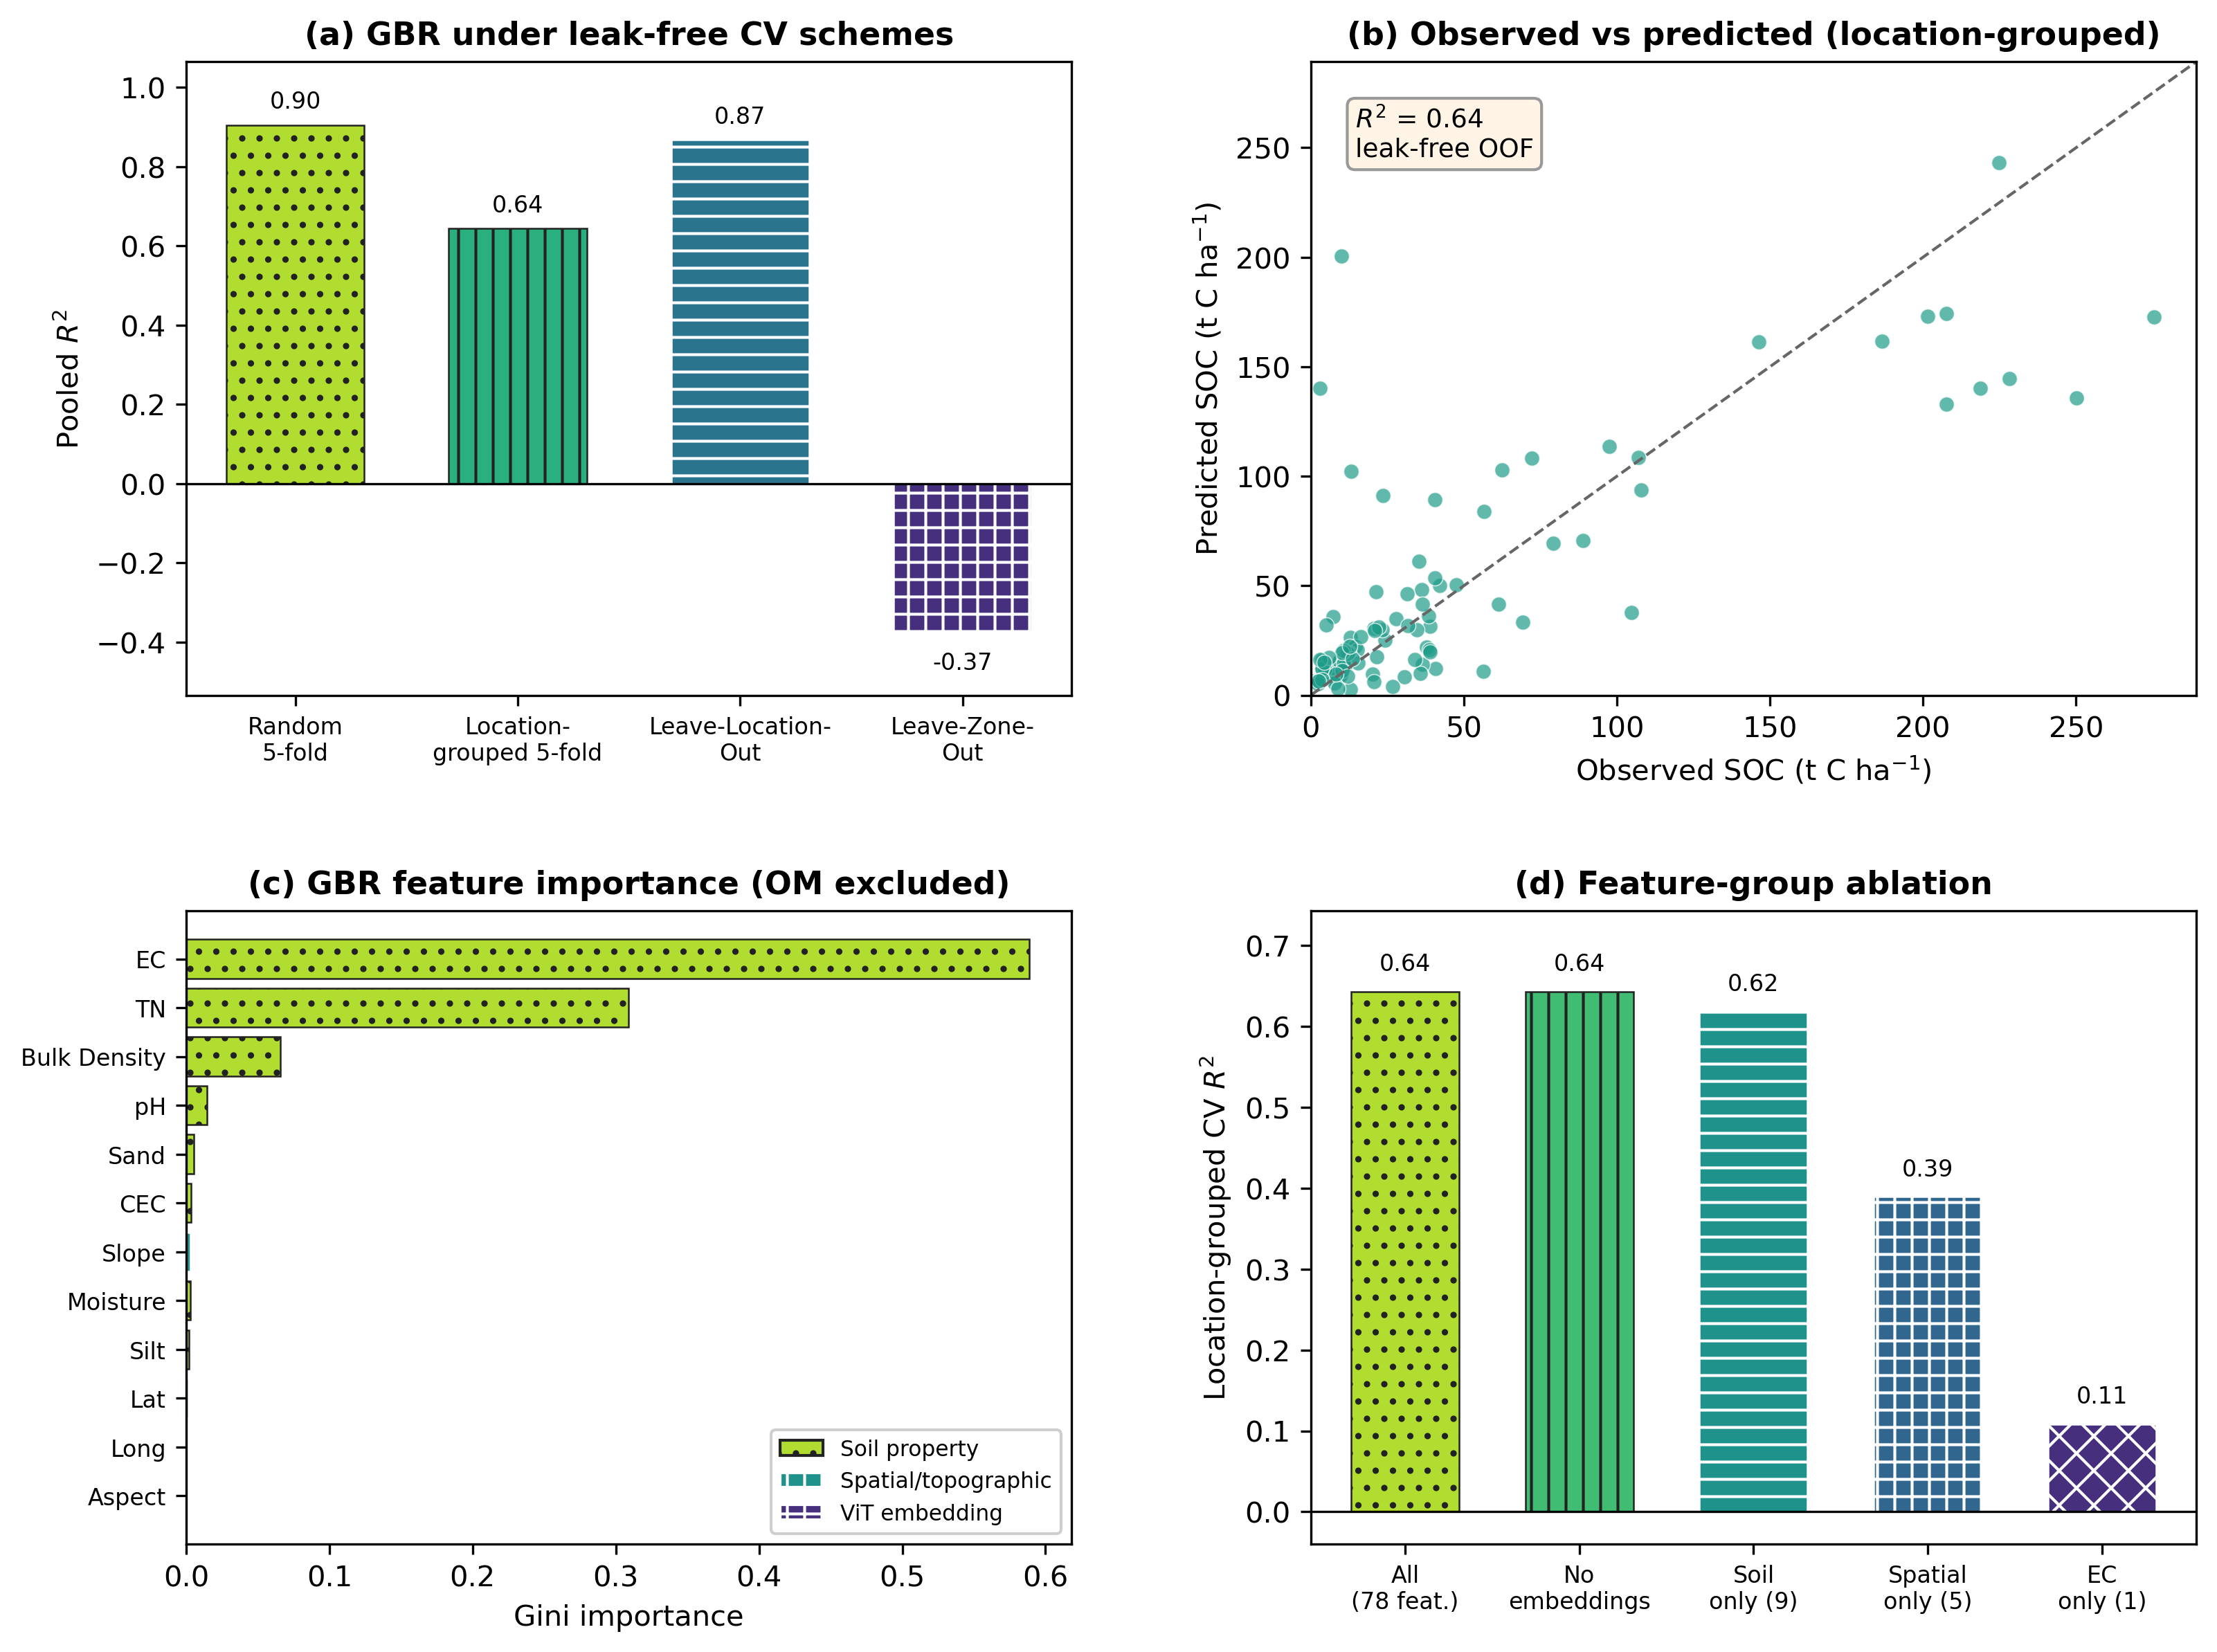

In [7]:
# Figure 4.
import importlib, make_fig4
importlib.reload(make_fig4)
from IPython.display import Image
Image("fig4_ml_dl.png", width=720)

## 5. H4 — cross-delta transferability

The motivating question: if a model trained on the Ganges learns 'SOC depends on EC, CEC, moisture, etc.', does that knowledge transfer to another delta?

We test this with a 15 × 15 train-on-delta-*i*, test-on-delta-*j* matrix. External data come from WoSIS 2023 (Batjes 2024) and BIS Nederland. Units are harmonised, but laboratory methods were not harmonised across the source datasets. The common predictor set is pH + clay + silt + sand (other variables are too sparsely co-measured in WoSIS).

Important null result: Asian monsoon deltas (Mekong, Irrawaddy, Godavari, Krishna) have SOC values but no co-measured texture/pH and so cannot enter a feature-based transfer test — itself a finding about the global data gap.

In [8]:
"""
H4 cross-delta transferability — definitive analysis.

Self-contained: reads h4_delta_samples.csv (4,504 complete-case top-metre profiles
across 14 global deltas, extracted from harmonised WoSIS profiles, Batjes 2024) plus
the in-house Ganges data. Predictor set = pH + clay + silt + sand (the variables
co-measured across deltas in WoSIS). SOC target in g/kg.

Produces:
  - transfer matrix (train delta i -> test delta j; diagonal = within-delta 5-fold CV)
  - forward (Ganges -> each delta) and reverse (pooled deltas -> Ganges) zero-shot
  - few-shot calibration curves; Leave-One-Delta-Out CV
  -> h4_results.json

Run:  python3 h4_analysis.py
"""
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import KFold

HERE = Path.cwd()
DATA = HERE.parent / "data"   # bundle layout: reproducibility/{scripts,data}
PREDICTORS = ["ph", "clay", "silt", "sand"]


def gbr():
    return make_pipeline(StandardScaler(),
                         GradientBoostingRegressor(random_state=42, n_estimators=200))


def main():
    df = pd.read_csv(DATA / "h4_delta_samples.csv")
    data = {d: (g[PREDICTORS].values, g["soc"].values)
            for d, g in df.groupby("delta")}

    # Ganges (SOC concentration % -> g/kg to match WoSIS orgc)
    g = pd.read_csv(DATA / "GangesSOC.csv"); g.columns = [c.strip() for c in g.columns]
    gx = g[["pH", "Clay", "Silt", "Sand"]].rename(
        columns={"pH": "ph", "Clay": "clay", "Silt": "silt", "Sand": "sand"}).dropna()
    gy = g.loc[gx.index, "SOCC"].values * 10.0
    data["Ganges"] = (gx[PREDICTORS].values, gy)

    names = list(data.keys())
    counts = {k: int(len(v[1])) for k, v in data.items()}
    print("samples:", counts, "| total ext =", sum(v for k, v in counts.items() if k != "Ganges"))

    # ---- transfer matrix ----
    M = pd.DataFrame(index=names, columns=names, dtype=float)
    for tr in names:
        Xtr, ytr = data[tr]
        m = gbr().fit(Xtr, ytr)
        for te in names:
            Xte, yte = data[te]
            if tr == te:
                if len(yte) >= 10:
                    p = np.full(len(yte), np.nan)
                    for a, b in KFold(5, shuffle=True, random_state=42).split(Xte):
                        p[b] = gbr().fit(Xte[a], yte[a]).predict(Xte[b])
                    M.loc[tr, te] = r2_score(yte, p)
            else:
                M.loc[tr, te] = r2_score(yte, m.predict(Xte))
    M.to_csv(HERE / "h4_transfer_matrix.csv")

    diag = np.array([M.loc[d, d] for d in names if not pd.isna(M.loc[d, d])])
    off = M.values[~np.eye(len(names), dtype=bool)].astype(float)
    off = off[~np.isnan(off)]

    res = {"source": "Harmonised WoSIS profiles (Batjes 2024)",
           "predictors": PREDICTORS, "n_deltas_external": len(names) - 1,
           "n_total_external": int(sum(v for k, v in counts.items() if k != "Ganges")),
           "sample_counts": counts,
           "within_delta_median_R2": round(float(np.median(diag)), 3),
           "within_delta_range": [round(float(diag.min()), 2), round(float(diag.max()), 2)],
           "cross_delta_median_R2": round(float(np.median(off)), 3),
           "cross_delta_frac_positive": round(float((off > 0).mean()), 3),
           "cross_delta_n_pairs": int(len(off))}

    # ---- forward / reverse zero-shot ----
    gX, gY = data["Ganges"]
    gmodel = gbr().fit(gX, gY)
    res["forward_ganges_to_delta"] = {
        d: round(float(r2_score(data[d][1], gmodel.predict(data[d][0]))), 3)
        for d in names if d != "Ganges"}

    ext = [d for d in names if d != "Ganges"]
    PX = np.vstack([data[d][0] for d in ext]); PY = np.concatenate([data[d][1] for d in ext])
    rev = gbr().fit(PX, PY)
    res["reverse_pooled_to_ganges"] = {
        "train_n": int(len(PY)), "R2": round(float(r2_score(gY, rev.predict(gX))), 3),
        "r": round(float(np.corrcoef(gY, rev.predict(gX))[0, 1]), 3)}

    # reverse few-shot
    rng = np.random.default_rng(7); curve = {}
    for nloc in (0, 5, 10, 15, 20):
        r2s = []
        for _ in range(20):
            idx = rng.permutation(len(gY)); loc, rest = idx[:nloc], idx[nloc:]
            mm = rev if nloc == 0 else gbr().fit(np.vstack([PX, gX[loc]]),
                                                 np.concatenate([PY, gY[loc]]))
            r2s.append(r2_score(gY[rest], mm.predict(gX[rest])))
        curve[nloc] = round(float(np.mean(r2s)), 3)
    res["reverse_few_shot"] = curve

    # ---- LODO ----
    grp = np.concatenate([np.full(len(data[d][1]), i) for i, d in enumerate(ext)])
    lodo = {}
    for i, d in enumerate(ext):
        tr = grp != i; te = grp == i
        if te.sum() >= 5:
            lodo[d] = round(float(r2_score(PY[te], gbr().fit(PX[tr], PY[tr]).predict(PX[te]))), 3)
    res["lodo"] = lodo

    (HERE / "h4_results.json").write_text(json.dumps(res, indent=2))
    print("\n=== TRANSFER MATRIX (rows=train, cols=test) ===")
    print(M.round(2).to_string())
    print("\n=== SUMMARY ===")
    print(json.dumps({k: v for k, v in res.items() if k != "sample_counts"}, indent=2))

main()

# --- display the result table inline ---
pd.read_csv("h4_transfer_matrix.csv", index_col=0).round(2)

samples: {'Amazon': 50, 'Chao Phraya': 171, 'Danube': 39, 'Indus': 88, 'Limpopo': 177, 'Mackenzie': 69, 'Mississippi': 985, 'Niger': 255, 'Parana-Plata': 151, 'Pearl': 38, 'Rhine-Meuse': 2316, 'Sacramento': 149, 'Senegal': 24, 'Yellow River': 277, 'Ganges': 100} | total ext = 4789



=== TRANSFER MATRIX (rows=train, cols=test) ===
              Amazon  Chao Phraya  Danube   Indus  Limpopo  Mackenzie  Mississippi  Niger  Parana-Plata   Pearl  Rhine-Meuse  Sacramento  Senegal  Yellow River  Ganges
Amazon         -0.25        -0.52   -0.40  -57.71    -0.06      -0.21        -0.27  -0.33         -0.32   -0.15        -0.35       -0.13   -30.03        -22.74   -0.36
Chao Phraya    -0.32         0.03    0.08  -13.97    -0.10      -0.14        -0.04  -0.28          0.02   -0.35        -0.44       -0.02    -2.11         -5.04    0.00
Danube        -74.22      -240.00   -0.14   -7.43    -0.50       0.32        -3.14  -7.48        -20.29   -4.88        -0.09       -0.91   -47.82        -27.16   -1.55
Indus          -0.12        -0.08   -0.06    0.61    -0.09      -0.27        -0.01  -0.23         -0.27   -0.09        -0.49       -0.03     0.13         -0.34   -0.26
Limpopo      -457.49      -139.41   -2.38 -259.57     0.18     -14.15       -29.93 -59.77        -15.08  -98.74

,Amazon,Chao Phraya,Danube,Indus,Limpopo,Mackenzie,Mississippi,Niger,Parana-Plata,Pearl,Rhine-Meuse,Sacramento,Senegal,Yellow River,Ganges
Amazon,-0.25,-0.52,-0.40,-57.71,-0.06,-0.21,-0.27,-0.33,-0.32,-0.15,-0.35,-0.13,-30.03,-22.74,-0.36
Chao Phraya,-0.32,0.03,0.08,-13.97,-0.10,-0.14,-0.04,-0.28,0.02,-0.35,-0.44,-0.02,-2.11,-5.04,0.00
Danube,-74.22,-240.00,-0.14,-7.43,-0.50,0.32,-3.14,-7.48,-20.29,-4.88,-0.09,-0.91,-47.82,-27.16,-1.55
Indus,-0.12,-0.08,-0.06,0.61,-0.09,-0.27,-0.01,-0.23,-0.27,-0.09,-0.49,-0.03,0.13,-0.34,-0.26
Limpopo,-457.49,-139.41,-2.38,-259.57,0.18,-14.15,-29.93,-59.77,-15.08,-98.74,-9.76,-2.11,-378.57,-336.36,-2.92
Mackenzie,-59.96,-176.96,0.48,-81.10,-0.59,-0.23,-2.41,-6.45,-20.82,-0.01,-0.32,-1.22,-12.83,-38.74,-1.38
Mississippi,-4.27,-19.07,-0.06,-1.90,-0.23,-0.31,-0.37,-2.37,-0.56,-0.30,-0.42,-0.06,-3.30,-1.47,-0.26
Niger,-9.07,-10.36,0.21,-61.22,-0.11,-0.23,-0.06,0.22,-1.08,-0.81,-0.36,-0.16,-178.14,-22.58,0.14
Parana-Plata,-2.89,-6.67,0.15,-5.80,-0.10,0.07,-0.18,-0.37,0.61,-0.65,-0.29,0.08,-19.71,-5.70,-0.47
Pearl,-0.90,-1.09,0.03,-8.07,-0.03,-0.08,-0.19,-0.18,-0.13,0.59,-0.22,0.08,-15.28,-4.43,-0.08


wrote fig5_transfer.png
within median=+0.04  cross median=-0.53  cross %>0=8%


wrote fig5_transfer.png
within median=+0.04  cross median=-0.53  cross %>0=8%


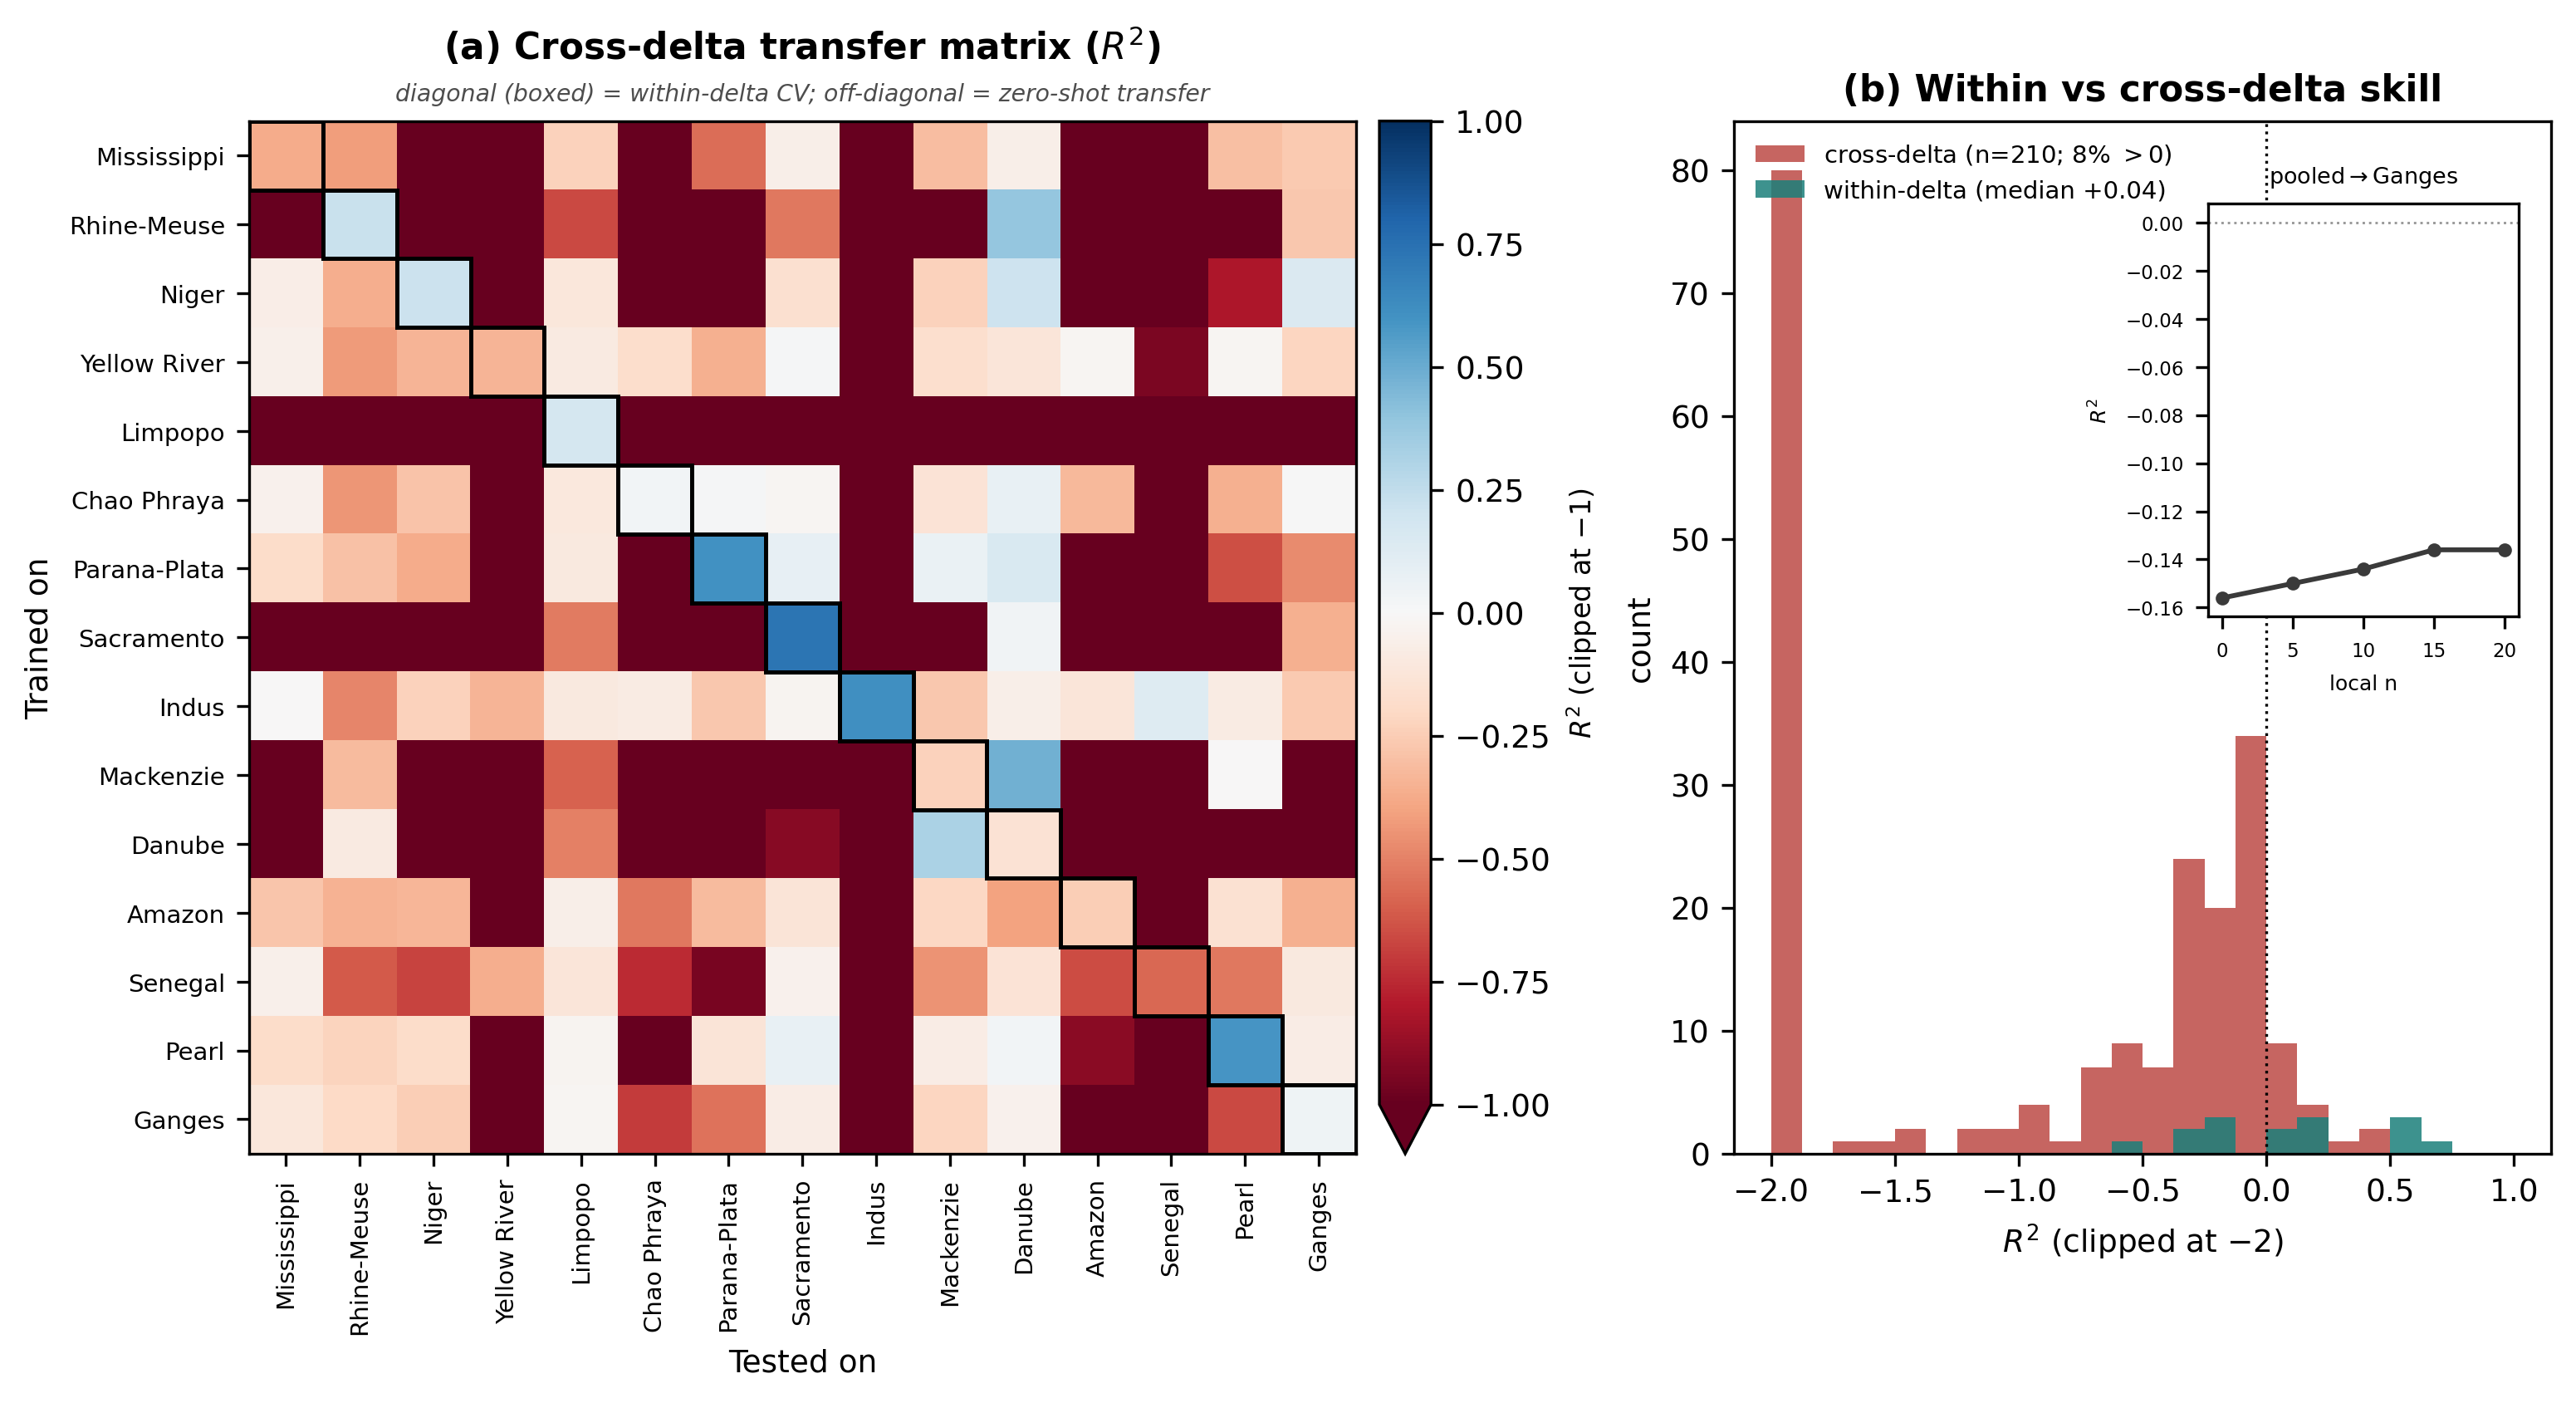

In [9]:
# Figure 5 — transfer matrix.
import importlib, make_fig5
importlib.reload(make_fig5)
from IPython.display import Image
Image("fig5_transfer.png", width=720)

**Read the matrix as:** the diagonal (boxed in Fig 5a) is within-delta CV — the model genuinely learns SOC where data is adequate. Off-diagonal cells are near-uniformly dark red (R² < 0): training on one delta does not generalise to another. Forward (Ganges → world) fails for all 14; reverse (pooled 14 → Ganges) gives R² ≈ −0.16 on v4 data. **Pooling does not enable cross-delta transfer.** This is a strong, expected pedometric result and the reason the manuscript advocates *layered transferability*: only higher-level structures (methodology, process-model form) transfer; learned weights do not.

wrote fig6_hypo3_spatial.png
per-zone LZO R^2: {'Tidal Active': -0.66, 'Active Delta': -11.2, 'Mature Delta': -2.99, 'Moribund Delta': -2.06} | LOLO: 0.867


wrote fig6_hypo3_spatial.png
per-zone LZO R^2: {'Tidal Active': -0.66, 'Active Delta': -11.2, 'Mature Delta': -2.99, 'Moribund Delta': -2.06} | LOLO: 0.867


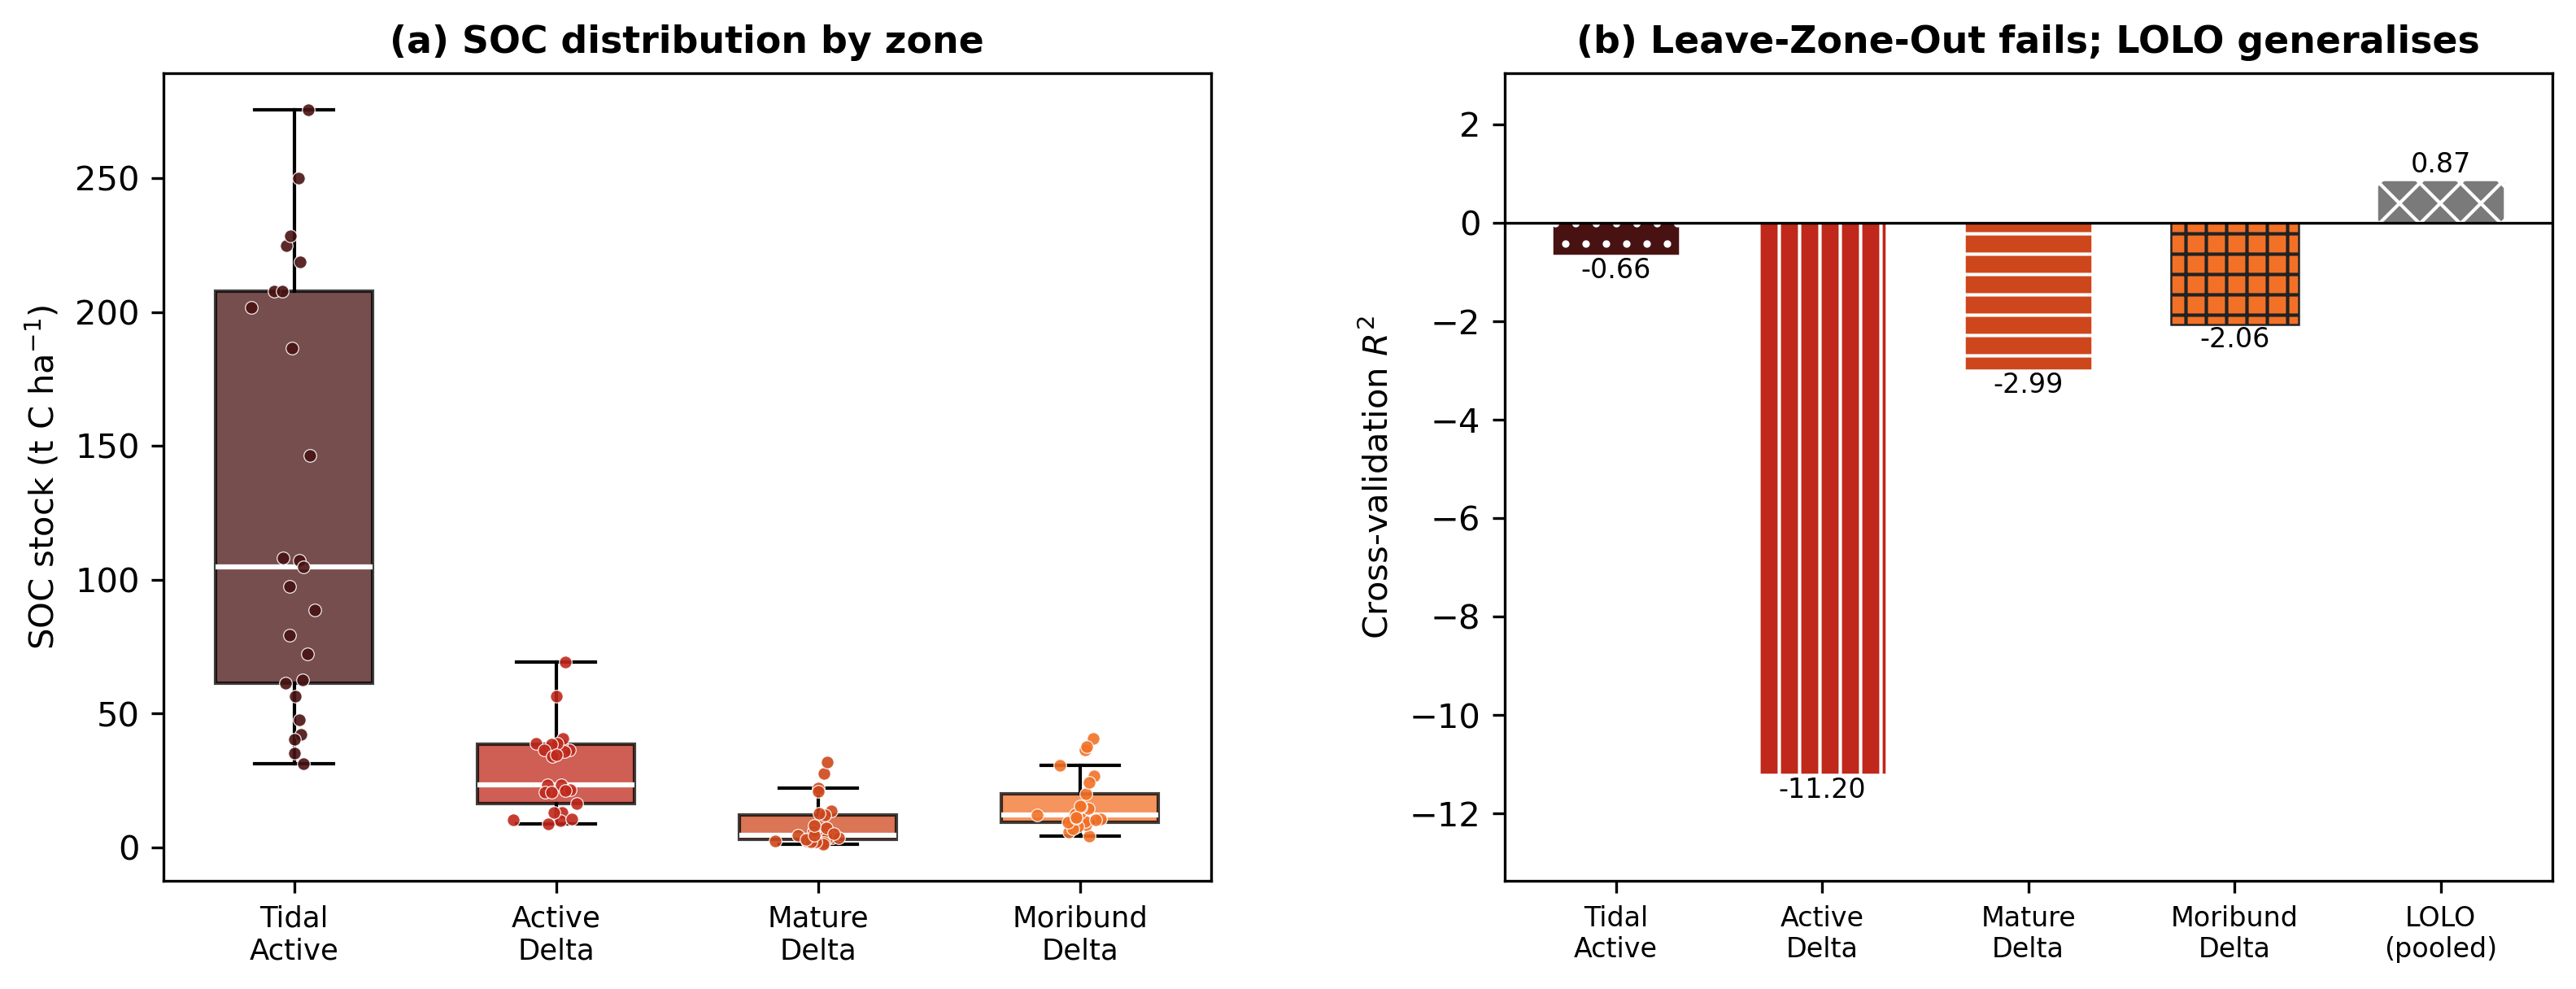

In [10]:
# Figure 6 — SI: H3 spatial structure.
import importlib, make_fig6
importlib.reload(make_fig6)
from IPython.display import Image
Image("fig6_hypo3_spatial.png", width=720)

## 6. Figure 1 — study area

Requires the GIS layers in `../data/gis/`; the DEM (~183 MB) is in the Zenodo archive only. Skipped gracefully if absent.

In [11]:
try:
    import importlib, create_study_area_figure
    importlib.reload(create_study_area_figure)
    from IPython.display import Image
    Image("fig1_study_area.png", width=720)
except FileNotFoundError as e:
    print(f"Skipped: {e}")

---
# 7. Exploration cells

Everything below is yours to extend. Suggested directions:

* Try a different ML model on the leak-free CV (Random Forest, LightGBM).
* Add other deltas to the H4 panel (the bounding-box dictionary is in `scripts/h4_analysis.py` / `provenance/wosis_extraction.py`).
* Add a Bayesian uncertainty quantification on the GBR predictions.
* Investigate which features carry signal *within* a delta but not *between*   — the explanation for the transfer-failure asymmetry.


In [12]:
# YOUR EXPLORATION HERE


In [13]:
# YOUR EXPLORATION HERE


In [14]:
# YOUR EXPLORATION HERE
